In [1]:
# ============================================================
# Imports
# ============================================================

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pkg_resources

from biocommons.seqrepo.fastadir.fabgz import FabgzReader

try:
    from handle_seqrepo import (
        load_SeqRepo,
        get_repofiles,
        get_clean_seq,
        write_fasta,
        mk_ClusterTable,
    )
except ModuleNotFoundError:
    import sys

    sys.path.append("../../utils")

    from handle_seqrepo import (
        load_SeqRepo,
        get_repofiles,
        get_clean_seq,
        write_fasta,
        mk_ClusterTable,
    )


# ============================================================
# Configuration
# ============================================================

SEQREPO_DIR = Path(
    "/Users/elisabeth/Documents/S.dysgalactiae/"
    "all_dys_data/dysgalactiae_project/data/"
    "SeqRepo/dysgalactiae"
)

OUTPUT_DIR = Path(
    "../../../data/manuscript/dysgalactiae"
)

REPO_NAME = "dysgalactiae_repo"

MIN_SEQUENCE_LENGTH = 30



/var/folders/bq/lsjh8s7s1217l3bjr1c437tw0000gn/T/ipykernel_43337/2996791758.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
# ============================================================
# Load SeqRepo
# ============================================================

sr = load_SeqRepo(str(SEQREPO_DIR))

all_files = get_repofiles(str(SEQREPO_DIR))
complete_files = get_clean_seq(
    all_files,
    str(SEQREPO_DIR)
)




def get_sequence_length(repo_file):
    """Return the length of a sequence stored in a Fabgz file."""

    reader = FabgzReader(repo_file)
    seq_id = reader.keys()[0]
    sequence = reader.fetch(seq_id)

    return len(sequence)


def get_all_genomes(repo_file, sr):
    """Return all genome IDs associated with a SeqRepo sequence."""

    reader = FabgzReader(repo_file)
    seq_id = reader.keys()[0]

    aliases = list(
        sr.aliases.find_aliases(seq_id)
    )

    return {
        record["namespace"]
        for record in aliases
        if str(record["alias"]).startswith("fig|")
    }


def is_exclusive_to_selected_genomes(repo_file, sr, selected_genomes):
    """Return True if sequence occurs only in the selected genomes."""

    sequence_genomes = get_all_genomes(repo_file, sr)

    return (
        bool(sequence_genomes)
        and sequence_genomes.issubset(selected_genomes)
    )


# ============================================================
# Exclude genomes from SeqRepo that should be omitted from downstream analysis
# ============================================================

genomes = {
    "1334.306",
    "1334.326",
    "1334.329",
    "1334.365",
}

all_files = [
    f
    for f in all_files
    if not is_exclusive_to_selected_genomes(
        f,
        sr,
        genomes
    )
]

complete_files = [
    f
    for f in complete_files
    if not is_exclusive_to_selected_genomes(
        f,
        sr,
        genomes
    )
]


# ============================================================
# Sequence lengths
# ============================================================

sequence_lengths = np.array([
    get_sequence_length(f)
    for f in all_files
])


# ============================================================
# Keep complete sequences longer than threshold
# ============================================================

chosen_files = [
    f
    for f in complete_files
    if get_sequence_length(f) > MIN_SEQUENCE_LENGTH
]


# ============================================================
# Summary
# ============================================================

print(
    f"""
SeqRepo summary
---------------
Unique sequences:                  {len(all_files):,}
Complete sequences:                {len(complete_files):,}
Sequences > {MIN_SEQUENCE_LENGTH} aa:               {(sequence_lengths > MIN_SEQUENCE_LENGTH).sum():,}
Complete sequences > {MIN_SEQUENCE_LENGTH} aa:      {len(chosen_files):,}
"""
)


SeqRepo summary
---------------
Unique sequences:                  67,474
Complete sequences:                67,049
Sequences > 30 aa:               67,042
Complete sequences > 30 aa:      66,619



In [3]:
# ============================================================
# Generate FASTA
# ============================================================

fasta_file = OUTPUT_DIR / f"{REPO_NAME}.fasta"

write_fasta(
    chosen_files,
    sr,
    str(fasta_file),
    exclude=genomes
)

# write_fasta also generates:
# {REPO_NAME}_frame.csv

,seguid,sequence,aliases,repository,genome_id,nbr_genomes
0,f1pe5zMhpkZdVx4Kh7YaRZmgIYM,MPDKPTKEKLMEQLKGGIIVSCQALPGEPLYSETGGIMPLMAKAAQ...,[119602.306:fig|119602.306.peg.378__N-acetylma...,/Users/elisabeth/Documents/S.dysgalactiae/all_...,"[1334.372, 1334.375, 119602.306, 119602.627, 1...",6
1,Cgejpw11ix011l7++o1AJFT6Uag,MSEVQWIKITTDIFDDEKIQLIESMPEGDTLIVIWFKLLVLAGKQN...,[119602.310:fig|119602.310.peg.1041__Phage rep...,/Users/elisabeth/Documents/S.dysgalactiae/all_...,"[1334.361, 119602.310]",2
2,1A6Efe5RKTMNwZSaXytCHK3G+yk,MDKKILEQLEFDKVKEQFRAYLQTEQGNRELDQLEPLNHHDKIKHY...,[119602.306:fig|119602.306.peg.309__Recombinat...,/Users/elisabeth/Documents/S.dysgalactiae/all_...,"[119602.78, 1334.195, 119602.306, 1334.218, 11...",7
3,do8BDIUwsNMJyHjScHUoEYQeVK8,MDIWTQLAAFAFLDTPKVALRPFQYADHAAFYAMVNDNEHLSYVFP...,[119602.310:fig|119602.310.peg.371__Ribosomal-...,/Users/elisabeth/Documents/S.dysgalactiae/all_...,"[119602.485, 452436.11, 119602.321, 119602.487...",6
4,7S4uby2VRmaeoXBfMFeoCkANZeE,MEEDEVDKYLTQISEADKERLGLTVLTHGDCNFRCKYCYEHFTNIS...,[119602.306:fig|119602.306.peg.768__Arylsulfat...,/Users/elisabeth/Documents/S.dysgalactiae/all_...,"[119602.69, 1334.226, 119602.78, 1334.195, 119...",9
...,...,...,...,...,...,...
66614,TCqHhfdFhpA7k4gzai1FnPfhylo,MTPHYLIADSGYKTPSIAHYLLTIGIIPVFSYTRPRNKKDMLRLKE...,[1334.139:fig|1334.139.peg.2003__Mobile elemen...,/Users/elisabeth/Documents/S.dysgalactiae/all_...,"[1334.39, 1334.139]",2
66615,77SmGmpD/Qt2qEIkGWwUOIKtdWs,MQLGLFELKKTAINHSDGHTTTNVTPKVTGKGQQYFINKFLNQEYLPV,[1334.139:fig|1334.139.peg.2143__Phage antirep...,/Users/elisabeth/Documents/S.dysgalactiae/all_...,[1334.139],1
66616,7P+G0dmocv25liCKHEQeBZqwHK0,MDDLTTAIIADEDNCYYTERGIEPLYAAPKTARIIIVGQAPGIVAQ...,[1334.139:fig|1334.139.peg.571__Hypothetical p...,/Users/elisabeth/Documents/S.dysgalactiae/all_...,"[99822.25, 1334.39, 1334.139]",3
66617,uNB3SY+cTU65f9F5AK4qrvmvYUw,MKQKRKLNNSKKRTKQLPFANTNLKKRHDIEYIEPYKKKMDRALKK...,[1334.139:fig|1334.139.peg.2083__FIG01120176: ...,/Users/elisabeth/Documents/S.dysgalactiae/all_...,[1334.139],1


In [6]:
def plot_sequence_lengths(
    sequence_lengths,
    bin_width=30,
    max_length=1800,
    save_path=None,
):

    data = np.asarray(sequence_lengths)

    bins = np.arange(
        0,
        max_length + bin_width,
        bin_width
    )

    # Pool sequences >= max_length into final bin
    data_plot = np.clip(
        data,
        0,
        max_length - 1
    )

    counts, edges = np.histogram(
        data_plot,
        bins=bins
    )

    # Remove empty bins
    keep = counts > 0

    counts = counts[keep]
    edges = edges[:-1][keep]

    # Equally spaced positions
    x = np.arange(len(counts))

    # Colors
    colors = ["#66a253"] * len(counts)
    colors[0] = "red"
    colors[-1] = "#33512a"

    # -------------------------
    # Plot
    # -------------------------

    plt.style.use("default")

    fig, ax = plt.subplots(
        figsize=(7, 5),
        facecolor="white"
    )

    ax.bar(
        x,
        counts,
        width=1,
        color=colors,
        edgecolor="black",
        linewidth=0.5
    )

    # -------------------------
    # X ticks
    # -------------------------

    target_lengths = [
        0, 300, 600,
        900, 1200, 1500
    ]

    tick_positions = []
    tick_labels = []

    for target in target_lengths:

        idx = np.argmin(
            np.abs(edges - target)
        )

        if idx not in tick_positions:
            tick_positions.append(idx)
            tick_labels.append(str(target))

    # Final pooled category
    if len(x) - 1 not in tick_positions:
        tick_positions.append(len(x) - 1)
        tick_labels.append(f"≥{max_length}")

    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels)

    # -------------------------
    # Styling
    # -------------------------

    ax.set_title(
        r"Sequence length in $\it{S.\ dysgalactiae}$",
        fontsize=16
    )

    ax.set_xlabel(
        "Sequence length [aa]",
        fontsize=14
    )

    ax.set_ylabel(
        "Number of sequences",
        fontsize=14
    )

    ax.tick_params(
        axis="both",
        labelsize=12
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_xlim(
        -0.55,
        len(x) - 0.45
    )

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

  #  return fig, ax

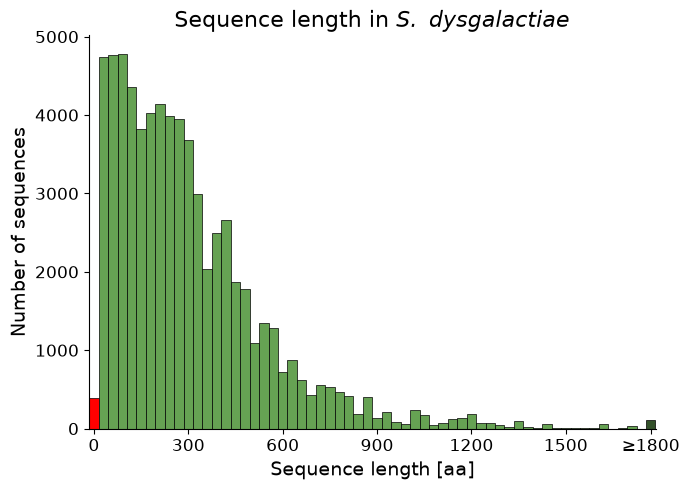

In [7]:
plot_sequence_lengths(
    sequence_lengths,
    save_path=OUTPUT_DIR / "sequence_length_dysgalactiae.png"
)